In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras import datasets, layers, models, Input
from sklearn.metrics import confusion_matrix, classification_report

# Etape 0 : chargement et exploration  du dataset MNIST
(X_train_raw, y_train), (X_test_raw, y_test) = datasets.mnist.load_data()

print("Forme des images d'entraînement :", X_train_raw.shape)
print("Forme des images de test :", X_test_raw.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Forme des images d'entraînement : (60000, 28, 28)
Forme des images de test : (10000, 28, 28)


Etape 1 : L'exploration visuelle des données (Grille de 0 à 9)

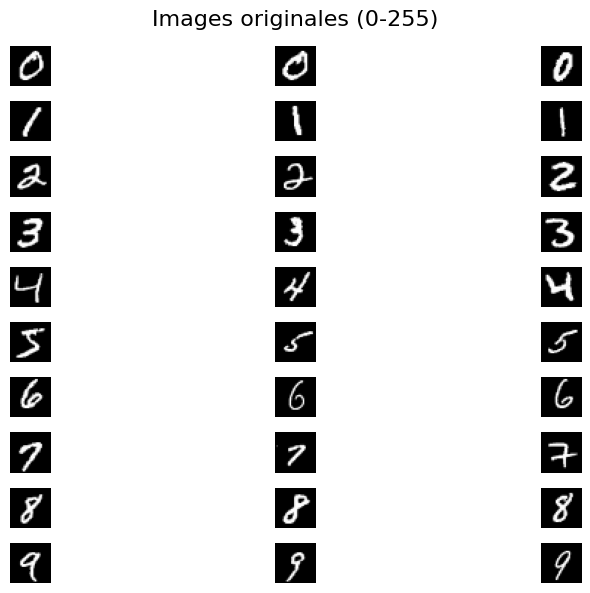

In [7]:
# On affiche 3 exemples d'images pour chaque chiffre de 0 à 9
plt.figure(figsize=(10, 6))

for digit in range(10):
    # On cherche les indices des 3 premières images correspondant au chiffre 'digit'
    idx = np.where(y_train == digit)[0][:3]
    for i, j in enumerate(idx):
        plt.subplot(10, 3, digit * 3 + i + 1)
        plt.imshow(X_train_raw[j], cmap='gray')
        plt.axis('off')

plt.suptitle("Images originales (0-255)", fontsize=16)
plt.tight_layout()
plt.subplots_adjust(top=0.92) # Pour ne pas coller le titre aux images
plt.show()

Etape 2: Prétraitement (Normalisation et ajout du canal)\
Les images brutes ont des valeurs de pixels comprises entre 0 et 255. De plus, un CNN s'attend à recevoir une dimension supplémentaire pour le canal de couleur (ici 1 car ce sont des images en nuances de gris)

In [ ]:
# Normalisation : on passe de [0, 255] à [0, 1]
X_train = X_train_raw.astype("float32") / 255.0
X_test = X_test_raw.astype("float32") / 255.0

# Ajout du canal : (N, 28, 28) devient (N, 28, 28, 1)
X_train = np.expand_dims(X_train, -1)
X_test = np.expand_dims(X_test, -1)

print("Formes finales après prétraitement :", X_train.shape, X_test.shape)

Formes finales après prétraitement : (60000, 28, 28, 1) (10000, 28, 28, 1)


Etape 3: Construction de l'architecture du CNN.\
 Voici l'architecture classique d'un petit CNN : des blocs de convolutions (Conv2D) et de réductions spatiales (MaxPooling2D), suivis d'un aplatissement (Flatten) et de couches denses classiques (Dense).   

In [ ]:
model = models.Sequential([
    Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),  # Coupe 50% des neurones au hasard pour éviter l'overfitting
    layers.Dense(10, activation="softmax") # 10 classes (chiffres de 0 à 9)
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,890 (511.29 KB)

 Trainable params: 130,890 (511.29 KB)

 Non-trainable params: 0 (0.00 B)

Etape 4 : Entrainement du modèle\
On lance l'entraînement en prélevant une partie du jeu d'entraînement pour la validation (validation_split=0.1), afin de garder le jeu de test totalement de côté.

In [ ]:
history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 53s 61ms/step - accuracy: 0.9200 - loss: 0.2602 - val_accuracy: 0.9858 - val_loss: 0.0513
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 79s 57ms/step - accuracy: 0.9783 - loss: 0.0734 - val_accuracy: 0.9882 - val_loss: 0.0390
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 49s 58ms/step - accuracy: 0.9839 - loss: 0.0555 - val_accuracy: 0.9907 - val_loss: 0.0335
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 85s 62ms/step - accuracy: 0.9871 - loss: 0.0436 - val_accuracy: 0.9897 - val_loss: 0.0376
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 79s 59ms/step - accuracy: 0.9884 - loss: 0.0371 - val_accuracy: 0.9908 - val_loss: 0.0320


Etape 5 : Évaluation et analyse des résultats \
Une fois l'entraînement terminé, on évalue la performance globale et on trace une matrice de confusion pour voir si le modèle confond certains chiffres (par exemple un 4 et un 9, ou un 3 et un 8).   

313/313 - 3s - 9ms/step - accuracy: 0.9904 - loss: 0.0318

Précision sur le test : 99.04%
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step


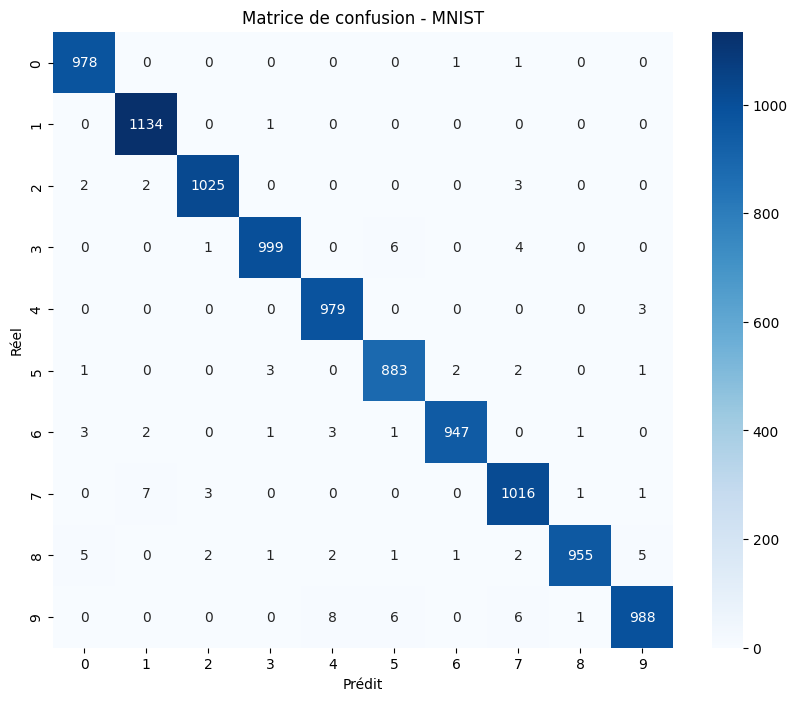

              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.99      0.99      0.99      1032
           3       0.99      0.99      0.99      1010
           4       0.99      1.00      0.99       982
           5       0.98      0.99      0.99       892
           6       1.00      0.99      0.99       958
           7       0.98      0.99      0.99      1028
           8       1.00      0.98      0.99       974
           9       0.99      0.98      0.98      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



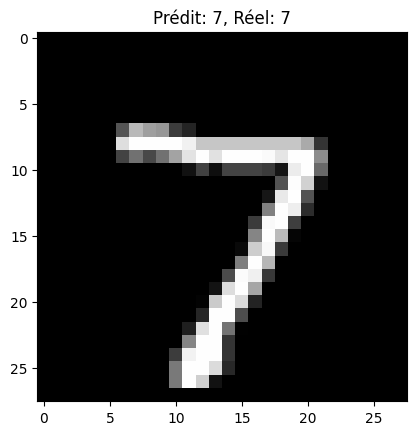

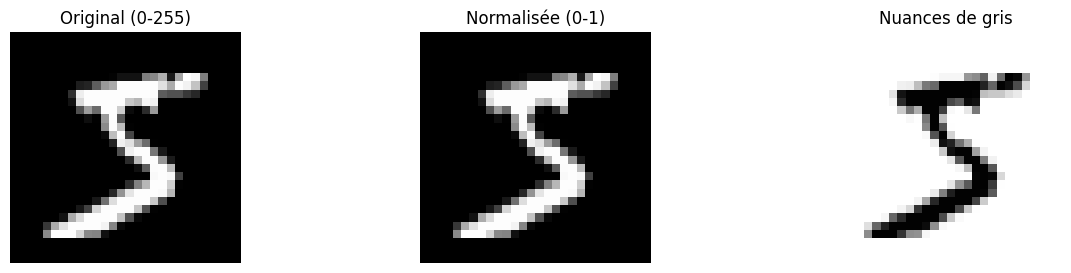

In [ ]:
# Évaluation sur le jeu de test final
loss, acc = model.evaluate(X_test, y_test, verbose=2)
print(f"\nPrécision sur le test : {acc * 100:.2f}%")

# Prédictions
y_pred = np.argmax(model.predict(X_test), axis=1)

# Matrice de confusion
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.title("Matrice de confusion - MNIST")
plt.show()

# Rapport de classification détaillé
print(classification_report(y_test, y_pred))

# Affichage de la première image du jeu de test avec sa prédiction
plt.imshow(X_test[0].reshape(28, 28), cmap="gray")
plt.title(f"Prédit: {y_pred[0]}, Réel: {y_test[0]}")
plt.show()

# Visualisation des étapes de prétraitement sur une image de "5"
img = X_train_raw[y_train == 5][0]   # image brute, valeurs de 0 à 255

plt.figure(figsize=(15, 3))

# 1. Image originale (brute)
plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title("Original (0-255)")
plt.axis('off')

# 2. Image normalisée (0 à 1)
img_norm = img.astype("float32") / 255.0   # même image, valeurs de 0 à 1
plt.subplot(1, 3, 2)
plt.imshow(img_norm, cmap='gray')
plt.title("Normalisée (0-1)")
plt.axis('off')

# 3. Image normalisée (avec une autre palette de couleurs)
plt.subplot(1, 3, 3)
plt.imshow(img_norm, cmap='Greys')
plt.title("Nuances de gris")
plt.axis('off')

plt.show()